In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from numpy import genfromtxt
from matplotlib import cm
from scipy.spatial.distance import cdist
import re
import math
import scipy
from scipy.stats import ks_2samp
from matplotlib.patches import Rectangle
import pathlib
from matplotlib import font_manager
from scipy.stats import fisher_exact
#from soursop.sstrajectory import SSTrajectory
from IPython.display import display, Markdown, HTML
import gseapy as gp
import matplotlib.colors as mcolors

In [2]:
# Setup the fonts
fonts_path = pathlib.Path.home().joinpath('fonts') # i.e. `~/fonts` (update as needed)
font_filename = 'ARIAL.TTF'
font_path = fonts_path.joinpath(font_filename)
print(font_path)

font_manager.fontManager.addfont(str(font_path))
prop = font_manager.FontProperties(fname=font_path)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()
plt.rcParams['pdf.fonttype'] = 42 # Makes text editiable
plt.rcParams['ps.fonttype'] = 42

COLOR_MAP = dict()
COLOR_MAP['A']         = '#8c8c8c'
COLOR_MAP['CHNQST']    = '#077a15'
COLOR_MAP['DE']        = '#e23a36'
COLOR_MAP['FWY']       = '#f58220'
COLOR_MAP['G']         = '#86bd8d'
COLOR_MAP['ILMV']      = '#231f20'
COLOR_MAP['KR']        = '#1725c2'
COLOR_MAP['P']         = '#c25fc9'


# Using the global color map, we convert the colormap of amino acid
# groups, to a map against individual amino acids. This
# serves as our internal color map which is used for styling.
aacolor_map=dict()
for amino_acids in COLOR_MAP:
    for amino_acid in amino_acids:
        aacolor_map[amino_acid] = COLOR_MAP[amino_acids]

/Users/magalhae/fonts/ARIAL.TTF


In [3]:
Ranked_matrix = pd.read_csv("/Users/magalhae/Desktop/FANCY_proteome/FANCY_20250630_Nucleolous_CoOMICS/NUCL_NPKL_FANCI_DDAplus_20250722/NUCL_FANCI_Input_rankedProteins.csv", low_memory = False)
Ranked_matrix = Ranked_matrix.set_index('UniprotID')
Ranked_matrix.head()

,NPKL_SRRM2_Ab_FANCI_LFQ_log,NUCL_NPM1_AB_FANCI_LFQ_log,NPKL_SRRM2_Ab_FANCI_Intencity,NUCL_NPM1_AB_FANCI_Intencity,NPKL_SRRM2_Ab_FANCI_Intencity_ranked,NUCL_NPM1_AB_FANCI_Intencity_ranked,cluster,NUCL_NPM1_AB_FANCI_1_x,NUCL_NPM1_AB_FANCI_3_x,NUCL_NPM1_AB_FANCI_4_x,...,NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_significant,Dyakov_Paraspeckle,Dyakov_nukl_spk,Dopie_Top400,NUCL_NPM1_AB_FANCI_1_y,NUCL_NPM1_AB_FANCI_3_y,NUCL_NPM1_AB_FANCI_4_y,NPKL_SRRM2_Ab_FANCI_1_y,NPKL_SRRM2_Ab_FANCI_2_y,NPKL_SRRM2_Ab_FANCI_3_y
UniprotID,,,,,,,,,,,,,,,,,,,,,
A0A024R1R8,5.239822,17.316305,30660.490,301687.936667,434.0,486.0,C5,0.826963,0.885954,0.817453,...,True,False,False,False,17.000993,18.090141,16.857782,15.719466,NaN,NaN
A3KN83,0.000000,9.681123,0.000,22649.665500,927.0,1414.0,C1,0.101602,0.000000,0.571562,...,False,False,False,False,13.648830,NaN,15.394539,NaN,NaN,NaN
A6NHR9,0.000000,9.884617,0.000,39430.287167,1377.0,1225.0,C1,0.366445,0.000000,0.473339,...,False,False,False,True,14.673004,NaN,14.980846,NaN,NaN,NaN
A8CG34,0.000000,9.725136,0.000,33606.883333,1912.0,1282.0,C1,0.332180,0.000000,0.375403,...,False,False,False,False,14.537636,NaN,14.637773,NaN,NaN,NaN
A8K2U0,14.691227,14.392850,53370.362,59863.201333,340.0,1042.0,C2,0.242118,0.091810,0.415533,...,False,False,False,False,14.182001,14.204226,14.792322,14.824190,14.418032,14.831459


In [4]:
Ranked_matrix['NUCL_NPKL_LFQ_ratio'] = (Ranked_matrix['NUCL_NPM1_AB_FANCI_LFQ_log'] + 1) / (Ranked_matrix['NPKL_SRRM2_Ab_FANCI_LFQ_log'] +1 )
Ranked_matrix['NUCL_NPKL_Int_ratio'] = (Ranked_matrix['NUCL_NPM1_AB_FANCI_Intencity'] + 1) / (Ranked_matrix['NPKL_SRRM2_Ab_FANCI_Intencity'] +1 )

In [5]:
Ranked_matrix['NUCL_NPKL_LFQ_ratio_rank'] = Ranked_matrix['NUCL_NPKL_LFQ_ratio'].rank(ascending=False, method='first')
Ranked_matrix['NUCL_NPKL_Int_ratio_rank'] = Ranked_matrix['NUCL_NPKL_Int_ratio'].rank(ascending=False, method='first')

In [6]:
from scipy import stats
Ranked_matrix['Z_Score_NUCL_NPKL_Int_ratio'] = stats.zscore(Ranked_matrix['NUCL_NPKL_Int_ratio'], nan_policy='omit')
Ranked_matrix['Z_Score_NUCL_NPKL_LFQ_ratio'] = stats.zscore(Ranked_matrix['NUCL_NPKL_LFQ_ratio'], nan_policy='omit')

In [7]:
Ranked_matrix.to_csv('Ranked_matrix.csv')

In [8]:
Mass_df = pd.read_csv("Mass_Uniprot.csv")
Mass_df = Mass_df.set_index('UniprotID')

In [9]:
Ranked_matrix = pd.merge(Ranked_matrix, Mass_df, how="left", left_index=True, right_index=True)

In [10]:
Ranked_matrix['True_intensity_NUCL_NPM1_AB_FANCI'] = Ranked_matrix['NUCL_NPM1_AB_FANCI_Intencity'] / Ranked_matrix['Mass']
Ranked_matrix['True_intensity_NPKL_SRRM2_Ab_FANCI'] = Ranked_matrix['NPKL_SRRM2_Ab_FANCI_Intencity'] / Ranked_matrix['Mass']

In [11]:
Ranked_matrix['NUCL_NPKL_Trueint_ratio'] = (Ranked_matrix['True_intensity_NUCL_NPM1_AB_FANCI'] + 1) / (Ranked_matrix['True_intensity_NPKL_SRRM2_Ab_FANCI'] +1 )
Ranked_matrix['NUCL_NPKL_TrueInt_ratio_rank'] = Ranked_matrix['NUCL_NPKL_Trueint_ratio'].rank(ascending=False, method='first')
Ranked_matrix['log_NUCL_NPKL_TrueInt_ratio'] = np.log2(Ranked_matrix['NUCL_NPKL_Trueint_ratio'])

In [12]:
dual_g = pd.read_csv("Dual_grammar_proteins.csv")
dual_g = list(dual_g['ProteinID'].values)

In [13]:
Ranked_matrix['log_NUCL_NPKL_Int_ratio'] = np.log2(Ranked_matrix['NUCL_NPKL_Int_ratio'])
Ranked_matrix['log_NUCL_NPKL_LFQ_ratio'] = np.log2(Ranked_matrix['NUCL_NPKL_LFQ_ratio'])
Ranked_matrix['Z_Score_log_NUCL_NPKL_LFQ_ratio'] = stats.zscore(Ranked_matrix['log_NUCL_NPKL_LFQ_ratio'], nan_policy='omit')

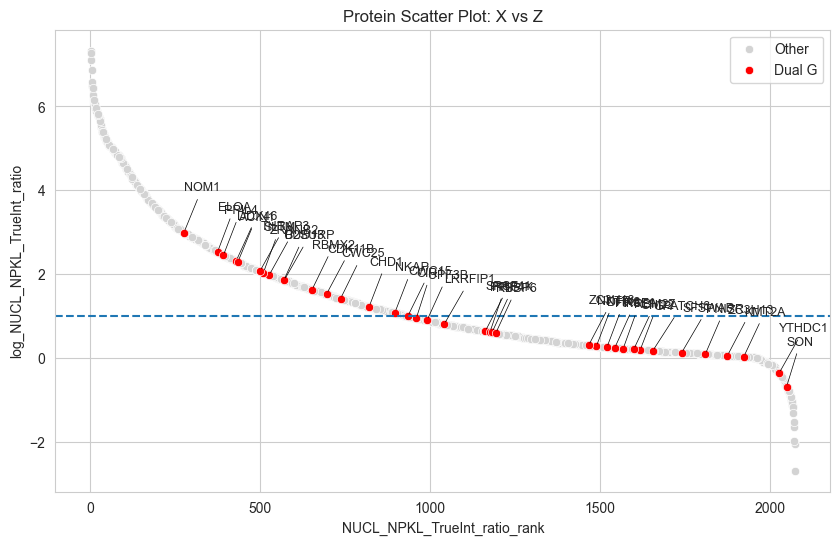

In [19]:
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# 2. Plot all points in light gray
sns.scatterplot(data=Ranked_matrix, x='NUCL_NPKL_TrueInt_ratio_rank', y='log_NUCL_NPKL_TrueInt_ratio', color='lightgray', label='Other')

# 3. Filter for dual_G proteins and plot them
highlight_df = Ranked_matrix.loc[Ranked_matrix.index.isin(dual_g)]
sns.scatterplot(data=highlight_df, x='NUCL_NPKL_TrueInt_ratio_rank', y='log_NUCL_NPKL_TrueInt_ratio', color='red', label='Dual G')

# 4. Add text labels for the highlighted proteins
for idx, row in highlight_df.iterrows():
    plt.annotate(
        text=row['Gene'],
        xy=(row['NUCL_NPKL_TrueInt_ratio_rank'], row['log_NUCL_NPKL_TrueInt_ratio']), 
        xytext=(row['NUCL_NPKL_TrueInt_ratio_rank'] + 1, row['log_NUCL_NPKL_TrueInt_ratio'] + 1), # Position of text
        arrowprops=dict(arrowstyle='-', color='black', lw=0.5), # Drawing the line
        fontsize=9
    )

plt.axhline(1, ls='--')

plt.title('Protein Scatter Plot: X vs Z')

plt.savefig("Ranking_NPM1_SRRM2__FANCI.pdf", format='pdf')
plt.savefig("Ranking_NPM1_SRRM2__FANCI.png", format='png', dpi=300)

plt.show()

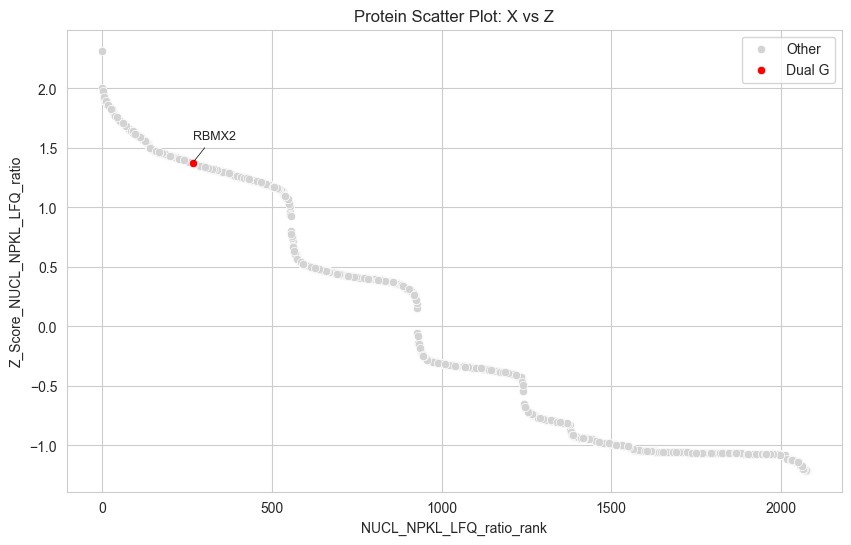

In [17]:
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# 2. Plot all points in light gray
sns.scatterplot(data=Ranked_matrix, x='NUCL_NPKL_LFQ_ratio_rank', y='Z_Score_NUCL_NPKL_LFQ_ratio', color='lightgray', label='Other')

# 3. Filter for dual_G proteins and plot them
highlight_df = Ranked_matrix.loc[Ranked_matrix.index.isin(['Q9Y388'])]
sns.scatterplot(data=highlight_df, x='NUCL_NPKL_LFQ_ratio_rank', y='Z_Score_NUCL_NPKL_LFQ_ratio', color='red', label='Dual G')

# 4. Add text labels for the highlighted proteins
for idx, row in highlight_df.iterrows():
    plt.annotate(
        text=row['Gene'],
        xy=(row['NUCL_NPKL_LFQ_ratio_rank'], row['Z_Score_NUCL_NPKL_LFQ_ratio']), 
        xytext=(row['NUCL_NPKL_LFQ_ratio_rank'] + 0.1, row['Z_Score_NUCL_NPKL_LFQ_ratio'] + 0.2), # Position of text
        arrowprops=dict(arrowstyle='-', color='black', lw=0.5), # Drawing the line
        fontsize=9
    )

plt.title('Protein Scatter Plot: X vs Z')
plt.show()

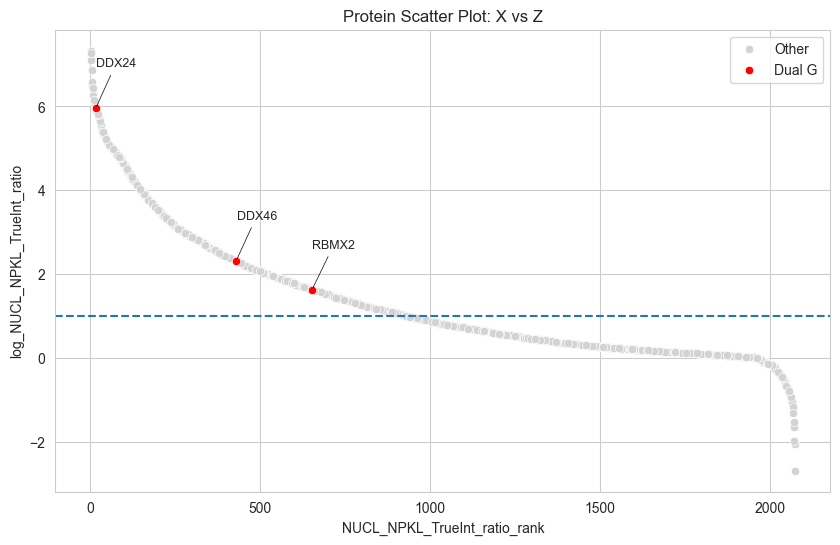

In [18]:
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# 2. Plot all points in light gray
sns.scatterplot(data=Ranked_matrix, x='NUCL_NPKL_TrueInt_ratio_rank', y='log_NUCL_NPKL_TrueInt_ratio', color='lightgray', label='Other')

# 3. Filter for dual_G proteins and plot them
highlight_df = Ranked_matrix.loc[Ranked_matrix.index.isin(['Q7L014', 'Q9Y388', 'Q9GZR7'])]
sns.scatterplot(data=highlight_df, x='NUCL_NPKL_TrueInt_ratio_rank', y='log_NUCL_NPKL_TrueInt_ratio', color='red', label='Dual G')

# 4. Add text labels for the highlighted proteins
for idx, row in highlight_df.iterrows():
    plt.annotate(
        text=row['Gene'],
        xy=(row['NUCL_NPKL_TrueInt_ratio_rank'], row['log_NUCL_NPKL_TrueInt_ratio']), 
        xytext=(row['NUCL_NPKL_TrueInt_ratio_rank'] + 1, row['log_NUCL_NPKL_TrueInt_ratio'] + 1), # Position of text
        arrowprops=dict(arrowstyle='-', color='black', lw=0.5), # Drawing the line
        fontsize=9
    )

plt.axhline(1, ls='--')

plt.title('Protein Scatter Plot: X vs Z')

plt.savefig("Ranking_NPM1_SRRM2__FANCI.pdf", format='pdf')
plt.savefig("Ranking_NPM1_SRRM2__FANCI.png", format='png', dpi=300)

plt.show()